# 1. Persiapan Data

### Dataset yang digunakan: **https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset**

### Jumlah Observasi (n): **2392 siswa**

### Variabel X: **Study Time Weekly dan Absences**

### Variabel Y: **GPA dan Grade Class**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.cross_decomposition import CCA
from sklearn.preprocessing import StandardScaler
from scipy import stats

In [2]:
from google.colab import files
files.upload()

Saving Student_performance_data _.csv to Student_performance_data _.csv


{'Student_performance_data _.csv': b'StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass\n1001,17,1,0,2,19.833722807854713,7,1,2,0,0,1,0,2.929195591667681,2.0\n1002,18,0,0,1,15.40875605584674,0,0,1,0,0,0,0,3.042914833436377,1.0\n1003,15,0,2,3,4.21056976881226,26,0,2,0,0,0,0,0.1126022544661815,4.0\n1004,17,1,0,3,10.028829473958215,14,0,3,1,0,0,0,2.0542181397029484,3.0\n1005,17,1,0,2,4.6724952729713305,17,1,3,0,0,0,0,1.2880611817953875,4.0\n1006,18,0,0,1,8.191218545250186,0,0,1,1,0,0,0,3.0841836144863937,1.0\n1007,15,0,1,1,15.601680474699295,10,0,3,0,1,0,0,2.748237414891583,2.0\n1008,15,1,1,4,15.424496305808074,22,1,1,1,0,0,0,1.360142712316461,4.0\n1009,17,0,0,0,4.562007558047703,1,0,2,0,1,0,1,2.896819189513569,2.0\n1010,16,1,0,1,18.444466363097202,0,0,3,1,0,0,0,3.5734742103297656,0.0\n1011,17,0,0,1,11.851363655296536,11,0,1,0,0,0,0,2.1471716250185144,3.0\n1012,17,0,0,1,7.5984858192402

In [3]:
df = pd.read_csv('Student_performance_data _.csv')
df

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2387,3388,18,1,0,3,10.680555,2,0,4,1,0,0,0,3.455509,0.0
2388,3389,17,0,0,1,7.583217,4,1,4,0,1,0,0,3.279150,4.0
2389,3390,16,1,0,2,6.805500,20,0,2,0,0,0,1,1.142333,2.0
2390,3391,16,1,1,0,12.416653,17,0,2,0,1,1,0,1.803297,1.0


# 2. Preprocessing Data

In [4]:
# Analisis Deskriptif
summary = df.describe()
summary.round(2)

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.00,2392.0,2392.00,2392.00,2392.00
mean,2196.50,16.47,0.51,0.88,1.75,9.77,14.54,0.30,2.12,0.38,0.30,0.2,0.16,1.91,2.98
std,690.66,1.12,0.50,1.03,1.00,5.65,8.47,0.46,1.12,0.49,0.46,0.4,0.36,0.92,1.23
min,1001.00,15.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
25%,1598.75,15.00,0.00,0.00,1.00,5.04,7.00,0.00,1.00,0.00,0.00,0.0,0.00,1.17,2.00
50%,2196.50,16.00,1.00,0.00,2.00,9.71,15.00,0.00,2.00,0.00,0.00,0.0,0.00,1.89,4.00
75%,2794.25,17.00,1.00,2.00,2.00,14.41,22.00,1.00,3.00,1.00,1.00,0.0,0.00,2.62,4.00
max,3392.00,18.00,1.00,3.00,4.00,19.98,29.00,1.00,4.00,1.00,1.00,1.0,1.00,4.00,4.00


In [5]:
# Cek missing value
print("Jumlah missing value:")
print(df.isnull().sum())

Jumlah missing value:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


In [6]:
# Set variabel X dan Y
X = df[['StudyTimeWeekly', 'Absences']]
Y = df[['GPA', 'GradeClass']]

In [7]:
# Standarisasi data
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_x.fit_transform(X)
Y_scaled = scaler_y.fit_transform(Y)

# 2. Correlation Structure

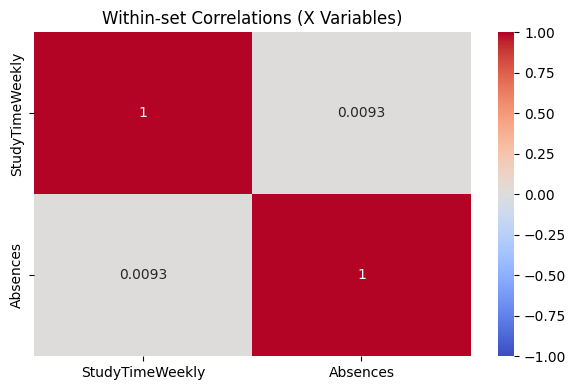

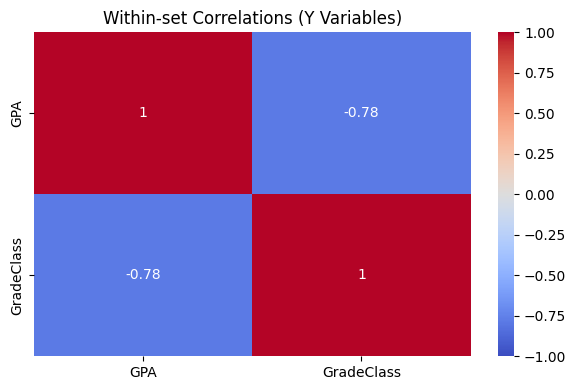

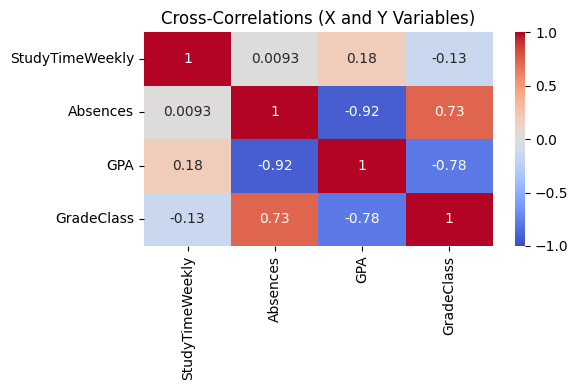

In [8]:
# Within-set correlations
within_corr_x = np.corrcoef(X_scaled.T)
within_corr_y = np.corrcoef(Y_scaled.T)

# Cross-Correlations
cross_corr = np.corrcoef(X_scaled.T, Y_scaled.T)

# Mendefinisikan nama label untuk variabel X dan Y
x_labels = ['StudyTimeWeekly', 'Absences']
y_labels = ['GPA', 'GradeClass']

# Heatmap untuk Within-set correlations (Variabel X)
plt.figure(figsize=(6, 4))
sns.heatmap(within_corr_x, annot=True, cmap='coolwarm', xticklabels=x_labels, yticklabels=x_labels, vmin=-1, vmax=1)
plt.title("Within-set Correlations (X Variables)")
plt.tight_layout()
plt.show()

# Heatmap untuk Within-set correlations (Variabel Y)
plt.figure(figsize=(6, 4))
sns.heatmap(within_corr_y, annot=True, cmap='coolwarm', xticklabels=y_labels, yticklabels=y_labels, vmin=-1, vmax=1)
plt.title("Within-set Correlations (Y Variables)")
plt.tight_layout()

# Heatmap untuk Cross-Correlations (Antara X dan Y)
# cross_corr berisi matriks korelasi gabungan [X, Y]
all_labels = x_labels + y_labels
plt.figure(figsize=(6, 4))
sns.heatmap(cross_corr, annot=True, cmap='coolwarm', xticklabels=all_labels, yticklabels=all_labels, vmin=-1, vmax=1)
plt.title("Cross-Correlations (X and Y Variables)")
plt.tight_layout()
plt.show()

# 3. Analisis CCA

In [9]:
# Lakukan CCA
cca = CCA(n_components=2,
          scale=True)
cca.fit(X_scaled, Y_scaled)

# Transformasi data ke ruang kanonikal
X_c, Y_c = cca.transform(X_scaled, Y_scaled)

# Hitung korelasi kanonikal
print("=== Canonical Correlation Analysis ===")
r = np.array([np.corrcoef(X_c[:, i], Y_c[:, i])[0, 1] for i in range(cca.n_components)])
print(f"Korelasi Kanonikal: {r}")

=== Canonical Correlation Analysis ===
Korelasi Kanonikal: [0.93838949 0.0125332 ]


# 4. Tentukan Canonical dan Cross Loadings

In [13]:
# Menghitung semua metrik hanya untuk Komponen 1
# 1. Weights
weights_x = cca.x_weights_[:, 0]
weights_y = cca.y_weights_[:, 0]

# 2. Loadings
loadings_x = np.corrcoef(X_scaled.T, X_c.T)[:2, 2]
loadings_y = np.corrcoef(Y_scaled.T, Y_c.T)[:2, 2]

# 3. Cross Loadings
cross_x = np.corrcoef(X_scaled.T, Y_c.T)[:2, 2]
cross_y = np.corrcoef(Y_scaled.T, X_c.T)[:2, 2]

# Menggabungkan ke dalam DataFrame ringkas agar tidak terpotong (truncated)
df_res_x = pd.DataFrame({
    'Canonical Weight': weights_x,
    'Canonical Loading': loadings_x,
    'Cross Loading': cross_x
}, index=X.columns)

df_res_y = pd.DataFrame({
    'Canonical Weight': weights_y,
    'Canonical Loading': loadings_y,
    'Cross Loading': cross_y
}, index=Y.columns)

print("=== ANALISIS CCA: VARIABEL X (INPUT) - KOMPONEN 1 ===")
display(df_res_x.round(6))

print("\n=== ANALISIS CCA: VARIABEL Y (OUTPUT) - KOMPONEN 1 ===")
display(df_res_y.round(6))

=== ANALISIS CCA: VARIABEL X (INPUT) - KOMPONEN 1 ===


,Canonical Weight,Canonical Loading,Cross Loading
StudyTimeWeekly,-0.199681,-0.190892,-0.179131
Absences,0.979861,0.979788,0.919423



=== ANALISIS CCA: VARIABEL Y (OUTPUT) - KOMPONEN 1 ===


,Canonical Weight,Canonical Loading,Cross Loading
GPA,-0.999777,-0.999916,-0.938311
GradeClass,0.021134,0.790820,0.742097


# 5. Hitung Variance Extracted & Redundancy

In [15]:
# Ambil nilai r dan r_squared hanya untuk Komponen 1
r_comp1 = r[0]
r_sq_comp1 = r_comp1**2

# Variance Extracted (Sudah untuk Komponen 1 saja dari sel sebelumnya)
ve_X = (X_loadings**2).mean(axis=0).values
ve_Y = (Y_loadings**2).mean(axis=0).values

# Redundancy untuk Komponen 1
red_X = ve_X * r_sq_comp1
red_Y = ve_Y * r_sq_comp1

# Membuat DataFrame Ringkas
summary = pd.DataFrame({
    'Canonical_r': [r_comp1],
    'r_squared': [r_sq_comp1],
    'Variance_Extracted_X': ve_X,
    'Variance_Extracted_Y': ve_Y,
    'Redundancy_X': red_X,
    'Redundancy_Y': red_Y
}, index=['Komponen 1'])

display(summary.round(4))

,Canonical_r,r_squared,Variance_Extracted_X,Variance_Extracted_Y,Redundancy_X,Redundancy_Y
Komponen 1,0.9384,0.8806,0.4982,0.8126,0.4387,0.7156


# 6. Lakukan Empirical Validation

In [16]:
# Empirical Validation
rng = np.random.default_rng(42)
observed_r = r[0]
n_perm = 1000
perm_r = []

for _ in range(n_perm):
    idx = rng.permutation(len(Y_scaled))
    Y_perm = Y_scaled[idx]
    cca_perm = CCA(n_components=1, scale=False, max_iter=1000)
    U_perm, V_perm = cca_perm.fit_transform(X_scaled, Y_perm)
    rp = np.corrcoef(U_perm[:,0], V_perm[:,0])[0,1]
    perm_r.append(rp)

perm_r = np.array(perm_r)
p_perm = (np.sum(perm_r >= observed_r) + 1) / (n_perm + 1)
print("Observed:", observed_r)
print("Permutation p-value:", p_perm)

Observed: 0.9383894938429423
Permutation p-value: 0.000999000999000999
